In [1]:
import pandas as pd, numpy as np, re, difflib
import matplotlib.pyplot as plt

agg_f = pd.read_csv("../data/processed/messages_clustered.csv", parse_dates=['first_date'])
CL, SZ = 'cl_tfidf', 'size_tfidf'
fam = agg_f[agg_f[SZ] >= 2].copy()
print("families:", fam[CL].nunique(), " messages:", len(fam))

families: 604  messages: 1588


In [10]:
num_re = re.compile(r"\d+(?:[.,]\d+)?")
url_re = re.compile(r"https?://\S+|www\.\S+")

def diff_features(a, b):
    ta, tb = a.split(), b.split()
    sm = difflib.SequenceMatcher(None, ta, tb, autojunk=False)
    ins = dele = rep = 0
    ops = sm.get_opcodes()
    for tag, i1, i2, j1, j2 in ops:
        if tag == 'insert':   ins += j2 - j1
        elif tag == 'delete': dele += i2 - i1
        elif tag == 'replace': rep += max(i2 - i1, j2 - j1)
    prefix = ops[0][0] == 'insert' and ops[0][1] == 0
    suffix = ops[-1][0] == 'insert' and ops[-1][1] == len(ta)
    return ins, dele, rep, prefix, suffix, sm.ratio()

rows = []
for cid, g in fam.groupby(CL):
    g = g.sort_values('first_dt')
    root = g.iloc[0]
    for _, r in g.iloc[1:].iterrows():
        ins, dele, rep, prefix, suffix, sim = diff_features(root['clean'], r['clean'])
        na, nb = set(num_re.findall(root['clean'])), set(num_re.findall(r['clean']))
        rows.append(dict(
            cluster=cid, family_size=len(g),
            words_added=ins, words_removed=dele, words_replaced=rep,
            prefix_added=prefix, suffix_added=suffix, similarity=sim,
            numbers_changed=(len(na) > 0 and len(nb) > 0 and na != nb),
            url_added=bool(url_re.search(r['text'])) and not bool(url_re.search(root['text'])),
            n_groups=r['n_groups'], max_sharings=r['max_sharings'], viral=r['viral'],
            root_sharings=root['max_sharings'],
        ))
pairs = pd.DataFrame(rows)
pairs.to_csv("../data/processed/mutation_pairs.csv", index=False)
print(len(pairs))
print(pairs.describe().T[['mean', '50%', 'max']])

984
                       mean          50%           max
cluster         6030.591463  5271.000000  16679.000000
family_size        3.953252     3.000000     15.000000
words_added       12.350610     0.000000   3835.000000
words_removed      4.940041     0.000000    519.000000
words_replaced    18.790650     4.000000    494.000000
similarity         0.795075     0.850168      0.999125
n_groups           1.513211     1.000000     24.000000
max_sharings       1.694106     1.000000     24.000000
viral              0.260163     0.000000      1.000000
root_sharings      2.901423     1.000000     47.000000


link added                    0.027439
text added at end (footer)    0.157520
text added at start           0.178862
numbers changed               0.197154
words dropped (>3)            0.202236
words added (>3)              0.290650
words reworded (>3)           0.535569
dtype: float64


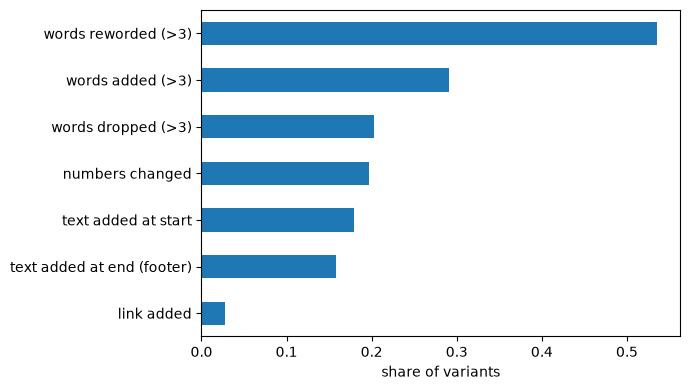

In [11]:
types = {
    "numbers changed": pairs['numbers_changed'].mean(),
    "text added at start": pairs['prefix_added'].mean(),
    "text added at end (footer)": pairs['suffix_added'].mean(),
    "link added": pairs['url_added'].mean(),
    "words dropped (>3)": (pairs['words_removed'] > 3).mean(),
    "words added (>3)": (pairs['words_added'] > 3).mean(),
    "words reworded (>3)": (pairs['words_replaced'] > 3).mean(),
}
s = pd.Series(types).sort_values()
s.plot.barh(figsize=(7, 4)); plt.xlabel("share of variants"); plt.tight_layout()
plt.savefig("../outputs/mutation_types.png", dpi=150)
print(s)

In [12]:
pairs['edit_size'] = 1 - pairs['similarity']
print(pairs[['edit_size', 'words_added', 'words_removed', 'n_groups', 'max_sharings']].corr(method='spearman').round(2))
print(pairs.groupby('suffix_added')[['n_groups', 'max_sharings']].mean())
print(pairs.groupby('numbers_changed')[['n_groups', 'max_sharings']].mean())

               edit_size  words_added  words_removed  n_groups  max_sharings
edit_size           1.00         0.11           0.12     -0.02         -0.05
words_added         0.11         1.00           0.01      0.04         -0.02
words_removed       0.12         0.01           1.00      0.05          0.03
n_groups           -0.02         0.04           0.05      1.00          0.80
max_sharings       -0.05        -0.02           0.03      0.80          1.00
              n_groups  max_sharings
suffix_added                        
False         1.505428      1.710495
True          1.554839      1.606452
                 n_groups  max_sharings
numbers_changed                        
False            1.532911      1.710127
True             1.432990      1.628866


In [13]:
from scipy.stats import mannwhitneyu, spearmanr

pairs['viral_variant'] = (pairs['max_sharings'] >= 2).astype(int)
print("share of variants with 2+ sharings:", round(pairs['viral_variant'].mean(), 3))

for f in ['numbers_changed', 'prefix_added', 'suffix_added', 'url_added']:
    a = pairs.loc[pairs[f], 'max_sharings']
    b = pairs.loc[~pairs[f], 'max_sharings']
    p = mannwhitneyu(a, b).pvalue
    print(f"{f:16s} n={len(a):4d} mean_with={a.mean():.2f} mean_without={b.mean():.2f} p={p:.3f}")

for c in ['edit_size', 'words_added', 'words_removed', 'words_replaced']:
    r, p = spearmanr(pairs[c], pairs['max_sharings'])
    print(f"{c:16s} spearman={r:.3f} p={p:.3f}")

share of variants with 2+ sharings: 0.26
numbers_changed  n= 194 mean_with=1.63 mean_without=1.71 p=0.028
prefix_added     n= 176 mean_with=1.50 mean_without=1.74 p=0.623
suffix_added     n= 155 mean_with=1.61 mean_without=1.71 p=0.222
url_added        n=  27 mean_with=1.37 mean_without=1.70 p=0.869
edit_size        spearman=-0.053 p=0.098
words_added      spearman=-0.022 p=0.490
words_removed    spearman=0.031 p=0.331
words_replaced   spearman=-0.047 p=0.140


In [14]:
from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score

cols = ['edit_size', 'words_added', 'words_removed', 'words_replaced',
        'numbers_changed', 'prefix_added', 'suffix_added', 'url_added']
X = pairs[cols].astype(float)
y = pairs['viral_variant']
groups = pairs['cluster']          # keeps each family entirely in train or test

models = {
    "logreg": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "gboost": GradientBoostingClassifier(random_state=0),
}
for name, clf in models.items():
    p = cross_val_predict(clf, X, y, cv=GroupKFold(n_splits=5), groups=groups, method="predict_proba")[:, 1]
    print(name, "AUC =", round(roc_auc_score(y, p), 3))
print("random guessing = 0.5")

logreg AUC = 0.553
gboost AUC = 0.507
random guessing = 0.5


In [15]:
txt = []
for cid, g in fam.groupby(CL):
    g = g.sort_values('first_dt')
    root = g.iloc[0]
    for _, r in g.iloc[1:].iterrows():
        txt.append((root['clean'], r['clean']))
pairs['root_text'] = [a for a, b in txt]
pairs['var_text'] = [b for a, b in txt]
pairs.to_csv("../data/processed/mutation_pairs.csv", index=False)

def changes(a, b):
    ta, tb = a.split(), b.split()
    sm = difflib.SequenceMatcher(None, ta, tb, autojunk=False)
    return [(tag, ' '.join(ta[i1:i2])[:90], ' '.join(tb[j1:j2])[:90])
            for tag, i1, i2, j1, j2 in sm.get_opcodes() if tag != 'equal']

def show(mask, title, k=3):
    print("\n#####", title)
    for _, r in pairs[mask].sample(min(k, int(mask.sum())), random_state=1).iterrows():
        print("-- family", r['cluster'], "| sharings", r['max_sharings'])
        for tag, old, new in changes(r['root_text'], r['var_text'])[:4]:
            print(f"   {tag:8s} OLD: {old!r}  ->  NEW: {new!r}")

show(pairs['numbers_changed'] & (pairs['words_replaced'] <= 3), "numbers changed")
show(pairs['suffix_added'], "footer added")
show(pairs['prefix_added'], "header added")
show(pairs['url_added'], "link added")


##### numbers changed
-- family 12428 | sharings 1
   replace  OLD: '28'  ->  NEW: '01'
-- family 4145 | sharings 7
   replace  OLD: '_terça-feira'  ->  NEW: '_segunda-feira'
   replace  OLD: '31/03/2020_'  ->  NEW: '30/03/2020_'
-- family 5305 | sharings 4
   insert   OLD: ''  ->  NEW: 'hidroxicloroquina desde o início do tratamento contra coronavírus.'
   delete   OLD: '.'  ->  NEW: ''
   delete   OLD: 'a gente vive numa realidade em que os aspectos que definem a civilização humanista estão d'  ->  NEW: ''

##### footer added
-- family 9693 | sharings 2
   replace  OLD: 'o'  ->  NEW: 'nosso'
   delete   OLD: 'jair bolsonaro'  ->  NEW: ''
   replace  OLD: 'essa demanda'  ->  NEW: 'bolsonaro'
   delete   OLD: 'por favor'  ->  NEW: ''
-- family 3997 | sharings 2
   insert   OLD: ''  ->  NEW: 'vai tudo caindo por terra, rebanho de safados'
-- family 2806 | sharings 1
   replace  OLD: 'indignificante'  ->  NEW: 'insignificante'
   replace  OLD: 'ter'  ->  NEW: 'ter,'
   replace  OLD: 'nã

In [16]:
from scipy.stats import mannwhitneyu

cta = r"urgente|compartilh|divulg|repass|espalh|bomba|atenção|atencao|vejam|assistam"
r_has = pairs['root_text'].str.contains(cta, regex=True)
v_has = pairs['var_text'].str.contains(cta, regex=True)
pairs['cta_added'] = v_has & ~r_has
pairs['cta_removed'] = r_has & ~v_has

print("urgency/share wording added:  ", round(pairs['cta_added'].mean(), 3))
print("urgency/share wording removed:", round(pairs['cta_removed'].mean(), 3))

for f in ['cta_added', 'cta_removed']:
    a, b = pairs.loc[pairs[f], 'max_sharings'], pairs.loc[~pairs[f], 'max_sharings']
    print(f, "n =", len(a), "| mean with =", round(a.mean(), 2),
          "| without =", round(b.mean(), 2), "| p =", round(mannwhitneyu(a, b).pvalue, 3))

for t in pairs.loc[pairs['cta_added'], 'var_text'].sample(5, random_state=2):
    print("-", t[:200])
    

urgency/share wording added:   0.04
urgency/share wording removed: 0.023
cta_added n = 39 | mean with = 1.56 | without = 1.7 | p = 0.625
cta_removed n = 23 | mean with = 1.87 | without = 1.69 | p = 0.068
- cdbr informa: estão gostando da amostra grátis de comunismo? repassado por: rômulo bittencourt coordenador nacional da (cdbr) - confederação direita brasil 1) governantes ineptos dando ordens sem sent
- atenção orientação de um promotor de justiça: jamais eu colocaria no atestado de óbito covid 19 sem a confirmação laboratorial. se essa pessoa tiver um seguro de vida e você atestar como covid-19, a s
- recebi e compartilho.... biografia do mandetta é de uma família de políticos do mato grosso do sul. como não conseguiu passar na faculdade federal de medicina do mato grosso do sul... cursou medicina,
- vazou!!! áudio de ricardo certi, assessor da casa civil do camilo para o sistema verdes mares. espalhem
- 05 de abril 2020 jejum e manifestação convidamos você para participar da nossa 

In [8]:
ties = fam.groupby(CL)['first_date'].agg(lambda s: s.nunique() < len(s)).mean()
print("share of families where 2+ messages share a first-seen date:", round(ties, 3))

share of families where 2+ messages share a first-seen date: 0.495


In [9]:
raw = pd.read_csv("../data/raw/covid19br.csv")
d = raw[(raw['midia'] == 0) & (raw['text'] != "<Arquivo de mídia oculto>")]
d = d[d['words'] >= 10].copy()

url_re2 = re.compile(r"https?://\S+|www\.\S+")
def clean(t):
    t = url_re2.sub(" ", t)
    t = re.sub(r"[^\w\s.,;:!?()%$/-]", " ", t)
    t = re.sub(r"\s+", " ", t).strip().lower()
    return t

d['clean'] = d['text'].apply(clean)
d['dt'] = pd.to_datetime(d['date'] + " " + d['hour'], format="%d/%m/%y %H:%M")
first_dt = d.groupby('clean')['dt'].min()

agg_f['first_dt'] = agg_f['clean'].map(first_dt)
print("missing timestamps:", agg_f['first_dt'].isna().sum())

fam = agg_f[agg_f[SZ] >= 2].copy()
ties = fam.groupby(CL)['first_dt'].agg(lambda s: s.nunique() < len(s)).mean()
print("families with tied first timestamps now:", round(ties, 3))

missing timestamps: 0
families with tied first timestamps now: 0.061


In [17]:
def edit_kinds(a, b):
    ta, tb = a.split(), b.split()
    sm = difflib.SequenceMatcher(None, ta, tb, autojunk=False)
    typo = real = 0
    for tag, i1, i2, j1, j2 in sm.get_opcodes():
        if tag == 'replace':
            old, new = ' '.join(ta[i1:i2]), ' '.join(tb[j1:j2])
            if difflib.SequenceMatcher(None, old, new).ratio() >= 0.8:
                typo += 1
            else:
                real += max(i2 - i1, j2 - j1)
    return typo, real

kinds = [edit_kinds(a, b) for a, b in zip(pairs['root_text'], pairs['var_text'])]
pairs['typo_fixes'] = [k[0] for k in kinds]
pairs['real_rewrites'] = [k[1] for k in kinds]

print("variants with spelling/punctuation-level fixes:", round((pairs['typo_fixes'] > 0).mean(), 3))
print("variants with >3 words truly rewritten:        ", round((pairs['real_rewrites'] > 3).mean(), 3))

variants with spelling/punctuation-level fixes: 0.387
variants with >3 words truly rewritten:         0.479


In [18]:
fam_covid = fam.groupby(CL)['is_covid'].any()
pairs['covid_family'] = pairs['cluster'].map(fam_covid)
print("covid families:", int(fam_covid.sum()), "of", len(fam_covid),
      "| covid variant pairs:", int(pairs['covid_family'].sum()))

g_ = pairs.groupby('covid_family')
tab = pd.DataFrame({
    "numbers_changed": g_['numbers_changed'].mean(),
    "header_added": g_['prefix_added'].mean(),
    "footer_added": g_['suffix_added'].mean(),
    "words_added>3": g_['words_added'].apply(lambda s: (s > 3).mean()),
    "words_dropped>3": g_['words_removed'].apply(lambda s: (s > 3).mean()),
    "real_rewrite>3": g_['real_rewrites'].apply(lambda s: (s > 3).mean()),
    "mean_edit_size": g_['edit_size'].mean(),
    "mean_sharings": g_['max_sharings'].mean(),
}).round(3)
print(tab.T)   # columns: False = non-COVID, True = COVID

covid families: 148 of 604 | covid variant pairs: 299
covid_family     False  True 
numbers_changed  0.187  0.221
header_added     0.142  0.264
footer_added     0.152  0.171
words_added>3    0.236  0.415
words_dropped>3  0.188  0.234
real_rewrite>3   0.445  0.555
mean_edit_size   0.220  0.171
mean_sharings    1.645  1.806


In [19]:
from scipy.stats import spearmanr

pairs['sharings_rel'] = pairs['max_sharings'] - pairs.groupby('cluster')['max_sharings'].transform('mean')
for c in ['edit_size', 'words_added', 'words_removed', 'real_rewrites']:
    r, p = spearmanr(pairs[c], pairs['sharings_rel'])
    print(f"{c:15s} spearman={r:.3f} p={p:.3f}")

edit_size       spearman=-0.015 p=0.638
words_added     spearman=-0.092 p=0.004
words_removed   spearman=-0.052 p=0.104
real_rewrites   spearman=-0.138 p=0.000


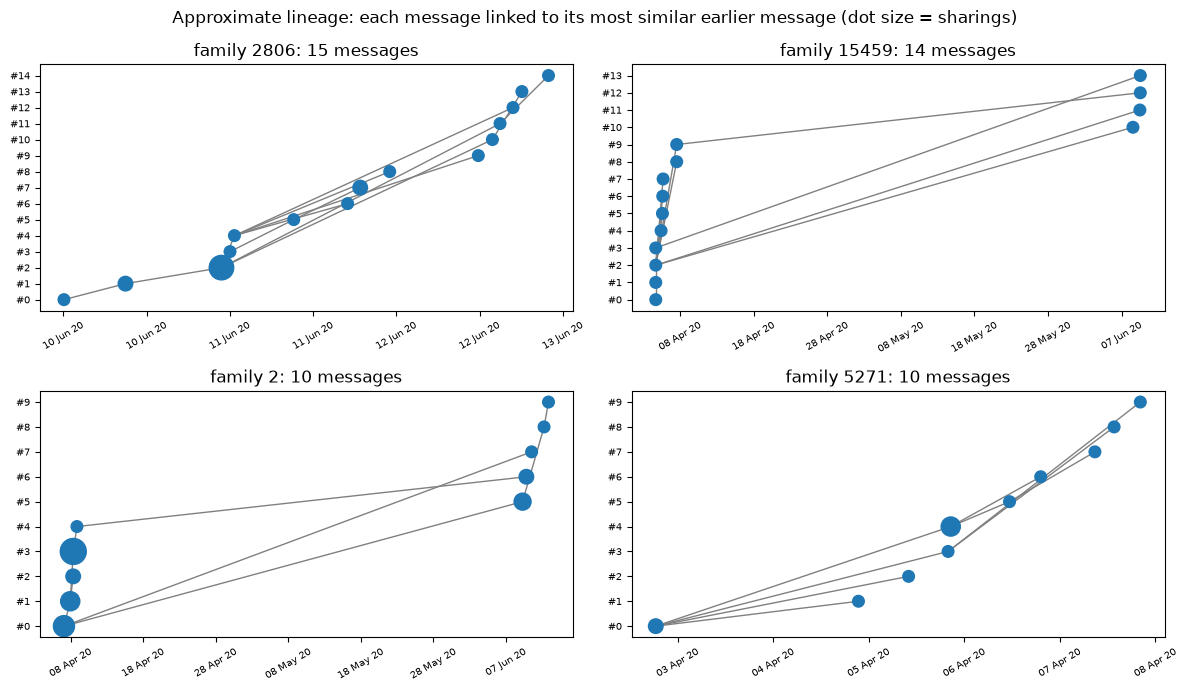

In [20]:
import matplotlib.dates as mdates

def build_lineage(g):
    g = g.sort_values('first_dt').reset_index(drop=True)
    parents = [-1]
    for i in range(1, len(g)):
        sims = [difflib.SequenceMatcher(None, g.loc[j, 'clean'].split(),
                                        g.loc[i, 'clean'].split(), autojunk=False).ratio()
                for j in range(i)]
        parents.append(int(np.argmax(sims)))
    g['parent'] = parents
    g['x'] = mdates.date2num(g['first_dt'])
    return g

ids = fam.groupby(CL).size().sort_values(ascending=False).index[:4]
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for ax, cid in zip(axes.ravel(), ids):
    g = build_lineage(fam[fam[CL] == cid])
    for i, r in g.iterrows():
        if r['parent'] >= 0:
            p = g.loc[int(r['parent'])]
            ax.plot([p['x'], r['x']], [int(r['parent']), i], color='gray', lw=1, zorder=1)
    ax.scatter(g['x'], range(len(g)), s=30 + 40 * g['max_sharings'], zorder=2)
    ax.set_title(f"family {cid}: {len(g)} messages")
    ax.set_yticks(range(len(g)))
    ax.set_yticklabels([f"#{i}" for i in range(len(g))], fontsize=7)
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%d %b %y'))
    ax.tick_params(axis='x', labelrotation=30, labelsize=7)
fig.suptitle("Approximate lineage: each message linked to its most similar earlier message (dot size = sharings)")
plt.tight_layout()
plt.savefig("../outputs/lineage_examples.png", dpi=150)
plt.show()

In [21]:
from scipy.stats import spearmanr

# rebuild each variant's timing in the same order that `pairs` was built
dts, ranks, vt = [], [], []
for cid, g in fam.groupby(CL):
    g = g.sort_values('first_dt')
    t0 = g['first_dt'].iloc[0]
    for k, (_, r) in enumerate(g.iloc[1:].iterrows(), start=1):
        dts.append((r['first_dt'] - t0).total_seconds() / 86400)
        ranks.append(k)
        vt.append(r['clean'])
assert vt == pairs['var_text'].tolist(), "row order mismatch, tell me"

pairs['days_since_root'] = dts
pairs['order_in_family'] = ranks
pairs['root_len'] = pairs['root_text'].str.split().str.len()
pairs['rewrite_rate'] = pairs['real_rewrites'] / pairs['root_len']

def partial_spearman(df, x, y, controls):
    R = df[[x, y] + controls].rank()
    Z = np.column_stack([np.ones(len(R))] + [R[c] for c in controls])
    rx = R[x] - Z @ np.linalg.lstsq(Z, R[x], rcond=None)[0]
    ry = R[y] - Z @ np.linalg.lstsq(Z, R[y], rcond=None)[0]
    return np.corrcoef(rx, ry)[0, 1]

def cluster_boot(df, x, y, controls, B=300, seed=0):
    rng = np.random.default_rng(seed)
    groups = {k: v for k, v in df.groupby('cluster')}
    keys = list(groups)
    out = []
    for _ in range(B):
        pick = rng.choice(keys, len(keys), replace=True)
        out.append(partial_spearman(pd.concat([groups[k] for k in pick], ignore_index=True), x, y, controls))
    return np.percentile(out, [2.5, 97.5])

r, p = spearmanr(pairs['days_since_root'], pairs['sharings_rel'])
print(f"days since root vs relative sharings: rho={r:.3f} p={p:.3f}")

rows = []
for x in ['real_rewrites', 'words_added', 'rewrite_rate']:
    raw = spearmanr(pairs[x], pairs['sharings_rel'])[0]
    ctl = ['days_since_root', 'root_len']
    part = partial_spearman(pairs, x, 'sharings_rel', ctl)
    lo, hi = cluster_boot(pairs, x, 'sharings_rel', ctl)
    rows.append(dict(feature=x, raw_rho=round(raw, 3), partial_rho=round(part, 3),
                     ci_low=round(lo, 3), ci_high=round(hi, 3)))
print(pd.DataFrame(rows).to_string(index=False))

days since root vs relative sharings: rho=-0.115 p=0.000
      feature  raw_rho  partial_rho  ci_low  ci_high
real_rewrites   -0.138       -0.099  -0.152   -0.046
  words_added   -0.092       -0.052  -0.106    0.007
 rewrite_rate   -0.067       -0.078  -0.126   -0.029


In [22]:
from scipy.stats import fisher_exact

tests = {
    "header_added": pairs['prefix_added'],
    "words_added>3": pairs['words_added'] > 3,
    "real_rewrite>3": pairs['real_rewrites'] > 3,
    "words_dropped>3": pairs['words_removed'] > 3,
    "numbers_changed": pairs['numbers_changed'],
    "footer_added": pairs['suffix_added'],
}
for name, m in tests.items():
    tab = pd.crosstab(pairs['covid_family'], m).reindex(index=[False, True], columns=[False, True], fill_value=0)
    odds, p = fisher_exact(tab.values)
    print(f"{name:16s} odds_ratio={odds:.2f} p={p:.4f}")

print("\nmedian root length in words (False = non-COVID, True = COVID):")
print(pairs.groupby('covid_family')['root_len'].median())

header_added     odds_ratio=2.18 p=0.0000
words_added>3    odds_ratio=2.29 p=0.0000
real_rewrite>3   odds_ratio=1.56 p=0.0018
words_dropped>3  odds_ratio=1.32 p=0.1019
numbers_changed  odds_ratio=1.23 p=0.2235
footer_added     odds_ratio=1.15 p=0.4486

median root length in words (False = non-COVID, True = COVID):
covid_family
False     32.0
True     185.0
Name: root_len, dtype: float64


In [23]:
from scipy.stats import mannwhitneyu

pairs['add_rate'] = pairs['words_added'] / pairs['root_len']
pairs['drop_rate'] = pairs['words_removed'] / pairs['root_len']
for c in ['add_rate', 'drop_rate', 'rewrite_rate', 'edit_size']:
    a = pairs.loc[pairs['covid_family'], c]
    b = pairs.loc[~pairs['covid_family'], c]
    print(f"{c:13s} covid median={a.median():.3f} non-covid median={b.median():.3f} p={mannwhitneyu(a, b).pvalue:.4f}")

add_rate      covid median=0.006 non-covid median=0.000 p=0.0162
drop_rate     covid median=0.000 non-covid median=0.000 p=0.6860
rewrite_rate  covid median=0.038 non-covid median=0.058 p=0.1424
edit_size     covid median=0.098 non-covid median=0.170 p=0.0000


In [24]:
pairs.to_csv("../data/processed/mutation_pairs_final.csv", index=False)
pd.DataFrame(rows).to_csv("../outputs/partial_correlations.csv", index=False)
print("saved")

saved
